In [12]:
############# forecast the land cover map based on historical maps and env variables ########
import os
import numpy as np
import rasterio
import pandas as pd
import torch
import matplotlib.pyplot as plt
import glob
from rasterio.plot import show
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from rasterio.enums import Resampling

import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm

In [3]:
class LandCoverCNN(nn.Module):
    def __init__(self):
        super(LandCoverCNN, self).__init__()

        # CNN branch for image patches
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.AdaptiveAvgPool2d(1)  # output shape: (batch, 64, 1, 1)

        # Fully connected branch for environmental variables
        self.fc_env = nn.Linear(2, 32)

        # Fusion and output
        self.fc1 = nn.Linear(64 + 32, 64)
        self.fc2 = nn.Linear(64, 3)  # output: 3 classes

    def forward(self, x_patch, x_env):
        # CNN path
        x = F.relu(self.conv1(x_patch))     # (batch, 32, 9, 9)
        x = F.relu(self.conv2(x))           # (batch, 64, 9, 9)
        x = self.pool(x).view(x.size(0), -1)  # (batch, 64)

        # Env path
        x_env = F.relu(self.fc_env(x_env))  # (batch, 32)

        # Concatenate and classify
        x = torch.cat((x, x_env), dim=1)    # (batch, 96)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [4]:
# Read the CSV file
csv_path = "/Volumes/MaloneLab/Research/Whitezone/Hydro_Salinity/Salinity/salinity_annual_avg.csv"
df = pd.read_csv(csv_path)

# Group by 'year' and calculate mean of 'annual_avg'
sa_df = df.groupby("year")["annual_avg"].mean().reset_index()

# Rename column for clarity
sa_df.columns = ["year", "mean_annual_salinity"]



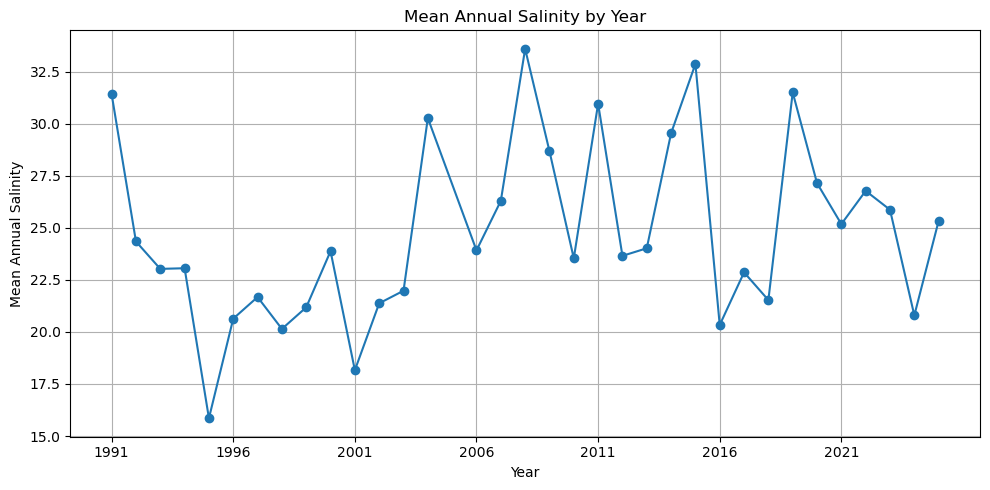

In [5]:
# Plotting
plt.figure(figsize=(10, 5))
plt.plot(sa_df["year"], sa_df["mean_annual_salinity"], marker='o', linestyle='-')

# Formatting
plt.xlabel("Year")
plt.ylabel("Mean Annual Salinity")
plt.title("Mean Annual Salinity by Year")
plt.grid(True)
plt.xticks(range(sa_df["year"].min(), sa_df["year"].max() + 1, 5))
plt.tight_layout()

# Show the plot
plt.show()

In [6]:
# Paths
raster_dir = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold08/CD_closest_GE"
wl_path = "/Volumes/MaloneLab/Research/Whitezone/Hydro_Salinity/Forecast/annual_mean_NAVD88_1984_2024.csv"

# Load env variables
wl_df = pd.read_csv(wl_path)
wl_df = wl_df[(wl_df['year'] >= 1991) & (wl_df['year'] <= 2024)]
wl_df = wl_df[wl_df['year'] != 2005]

sa_df = sa_df[(sa_df['year'] >= 1991) & (sa_df['year'] <= 2024)]

salinity_series = sa_df["mean_annual_salinity"].values
wl_series = wl_df["annual_mean_NAVD88"].values
years = sa_df["year"].values



In [7]:
raster_dir = "/Volumes/MaloneLab/Research/Whitezone/Result/Emulation/Final/CDthreshold08/CD_closest_GE"
all_rasters = sorted(glob.glob(os.path.join(raster_dir, "*.tif")))
# Filter images for 1991–2024
selected_rasters = [
    fp for fp in all_rasters 
    if any(str(yr) in os.path.basename(fp) for yr in range(1991, 2025) if yr != 2005)
]
image_stack = []
for path in selected_rasters:
    with rasterio.open(path) as src:
        img = src.read(1)  # No resampling needed
        image_stack.append(img)

image_stack = np.stack(image_stack)  # Shape: (years, height, width)
with rasterio.open(selected_rasters[0]) as src:
    meta = src.meta.copy()

In [8]:
def extract_patches(image_stack, salinity_series, wl_series, patch_size=9):
    pad = patch_size // 2
    X_patches = []
    X_env = []
    y_labels = []

    for t in range(image_stack.shape[0]):
        img = image_stack[t]
        sal = salinity_series[t]
        wl = wl_series[t]

        # Pad image to handle border cases
        padded_img = np.pad(img, pad, mode='constant', constant_values=0)

        for i in range(pad, pad + img.shape[0]):
            for j in range(pad, pad + img.shape[1]):
                label = padded_img[i, j]
                if label == 0:
                    continue  # skip no-data
                patch = padded_img[i-pad:i+pad+1, j-pad:j+pad+1]
                if np.any(patch == 0):  # skip patches with no-data
                    continue
                X_patches.append(patch)
                X_env.append([sal, wl])
                y_labels.append(label)

    X_patches = np.array(X_patches)  # shape: (samples, patch_size, patch_size)
    X_env = np.array(X_env)          # shape: (samples, 2)
    y_labels = np.array(y_labels)    # shape: (samples,)
    return X_patches, X_env, y_labels

X_patches, X_env, y = extract_patches(image_stack, salinity_series, wl_series, patch_size=9)

In [9]:
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim

y = y - 1
y_tensor = torch.tensor(y, dtype=torch.long)

# Assume: X_patches, X_env, y already defined (from Step 1)
X_patches_tensor = torch.tensor(X_patches, dtype=torch.float32)  # (N, 9, 9, 1)
X_patches_tensor = torch.tensor(X_patches, dtype=torch.float32).unsqueeze(1)  # (N, 1, 9, 9)
X_env_tensor = torch.tensor(X_env, dtype=torch.float32)                      # (N, 2)
y_tensor = torch.tensor(y, dtype=torch.long)         # (N,)

# Dataset and loader
dataset = TensorDataset(X_patches_tensor, X_env_tensor, y_tensor)
loader = DataLoader(dataset, batch_size=128, shuffle=True)

# Model, loss, optimizer
model = LandCoverCNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(10):
    model.train()
    running_loss = 0.0
    for xb, xenv, yb in loader:
        optimizer.zero_grad()
        outputs = model(xb, xenv)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1} - Loss: {running_loss:.4f}")

    # Save optimizer state dict
    torch.save({
    'epoch': epoch + 1,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss': running_loss,
    }, f"checkpoint_epoch_{epoch+1}.pth")

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Epoch 1 - Loss: 7096.0610
Epoch 2 - Loss: 2288.2457
Epoch 3 - Loss: 775.3772
Epoch 4 - Loss: 499.0950
Epoch 5 - Loss: 388.1789
Epoch 6 - Loss: 380.5129
Epoch 7 - Loss: 307.1406
Epoch 8 - Loss: 314.8230
Epoch 9 - Loss: 296.0156
Epoch 10 - Loss: 239.8118


In [14]:
base_img = image_stack[-1]

patch_size = 9
pad = patch_size // 2
padded_img = np.pad(base_img, pad_width=pad, mode='constant', constant_values=0)

H, W = base_img.shape
X_patches_future = []
X_env_future = []
row_indices = []
col_indices = []

# Apply +25% increase to last known sal/wl
sal_future = salinity_series[-1] * 1.25
wl_future = wl_series[-1] * 1.25

for row in tqdm(range(pad, H + pad)):
    for col in range(pad, W + pad):
        center_val = padded_img[row, col]
        if center_val == 0:
            continue  # skip no-data

        patch = padded_img[row - pad:row + pad + 1, col - pad:col + pad + 1]
        X_patches_future.append(patch[np.newaxis, :, :])  # shape (1, 9, 9)
        X_env_future.append([sal_future, wl_future])
        row_indices.append(row - pad)
        col_indices.append(col - pad)

X_patches_future = np.array(X_patches_future, dtype=np.float32)  # (N, 1, 9, 9)
X_env_future = np.array(X_env_future, dtype=np.float32)  

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 723/723 [00:01<00:00, 547.49it/s]


In [15]:
model = LandCoverCNN()
checkpoint = torch.load("models/checkpoint_epoch_10.pth")
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

LandCoverCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): AdaptiveAvgPool2d(output_size=1)
  (fc_env): Linear(in_features=2, out_features=32, bias=True)
  (fc1): Linear(in_features=96, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=3, bias=True)
)

In [16]:
with torch.no_grad():
    X_patches_tensor = torch.tensor(X_patches_future, dtype=torch.float32)
    X_env_tensor = torch.tensor(X_env_future, dtype=torch.float32)

    outputs = model(X_patches_tensor, X_env_tensor)
    preds = torch.argmax(outputs, dim=1).cpu().numpy() + 1  # Convert to class 1/2/3


In [18]:
predicted_raster = np.zeros((H, W), dtype=np.uint8)
for pred, row, col in zip(preds, row_indices, col_indices):
    predicted_raster[row, col] = pred

# Use the 2024 raster as reference
with rasterio.open(selected_rasters[-1]) as src:
    meta = src.meta.copy()

meta.update({
    "dtype": "uint8",
    "count": 1,
    "nodata": 0
})

with rasterio.open("predicted_landcover_future.tif", "w", **meta) as dst:
    dst.write(predicted_raster, 1)

In [20]:
reference_path = selected_rasters[-1]  # Assuming this is 2024

with rasterio.open(reference_path) as src:
    ref_meta = src.meta.copy()  # Contains width, height, crs, transform, etc.

# Update only what's different
ref_meta.update({
    "dtype": "uint8",
    "count": 1,       # number of bands
    "nodata": 0       # match your no-data value
})

with rasterio.open("predicted_landcover_future.tif", "w", **ref_meta) as dst:
    dst.write(predicted_raster, 1)  # 1-based indexing for band